In [1]:
# ============================================================
# STEP 1: IMPORT LIBRARIES
# ============================================================
import numpy as np
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

In [2]:
# ============================================================
# STEP 2: LOAD ALL FILES
# ============================================================
customers = pd.read_csv('RAW DATA/customers.csv', encoding= 'unicode_escape')
orders = pd.read_csv('RAW DATA/orders.csv', encoding= 'unicode_escape')  
products = pd.read_csv('RAW DATA/products.csv', encoding= 'unicode_escape')
sessions = pd.read_csv('RAW DATA/sessions.csv', encoding= 'unicode_escape')

# ============================================================
# STEP 3: INSPECT FIRST (always do this before cleaning)
# ============================================================
def inspect(df, name):
    print(f"\n===== {name} =====")
    print(f"Shape: {df.shape}")
    print(f"Columns: {list(df.columns)}")
    print(f"Missing values:\n{df.isnull().sum()}")
    print(f"Duplicates: {df.duplicated().sum()}")
    print(f"Data types:\n{df.dtypes}")
    print(df.head(3))

inspect(customers, "CUSTOMERS")
inspect(orders, "ORDERS")
inspect(products, "PRODUCTS")
inspect(sessions, "SESSIONS")


===== CUSTOMERS =====
Shape: (2500, 6)
Columns: ['customer_id', 'signup_date', 'city', 'age', 'gender', 'customer_segment']
Missing values:
customer_id         0
signup_date         0
city                0
age                 0
gender              0
customer_segment    0
dtype: int64
Duplicates: 0
Data types:
customer_id         int64
signup_date           str
city                  str
age                 int64
gender                str
customer_segment      str
dtype: object
   customer_id signup_date    city  age  gender    customer_segment
0        38584  2018-07-12  Mumbai   21  Female        Value Seeker
1        65430  2021-08-01  Mumbai   21    Male        Trend Seeker
2        60694  2016-02-01   Thane   57    Male  Essentials Shopper

===== ORDERS =====
Shape: (8000, 14)
Columns: ['order_id', 'product_id', 'customer_id', 'order_date', 'shipping_date', 'status', 'price', 'promised_delivery_date', 'actual_delivery_date', 'marketing_campaign', 'discount_pct', 'payment_method', '

In [3]:
# Convert date strings into actual datetime values
orders["order_date"] = pd.to_datetime(orders["order_date"], errors="coerce")
orders["shipping_date"] = pd.to_datetime(orders["shipping_date"], errors="coerce")
orders["promised_delivery_date"] = pd.to_datetime(orders["promised_delivery_date"], errors="coerce")
orders["actual_delivery_date"] = pd.to_datetime(orders["actual_delivery_date"], errors="coerce")
customers["signup_date"] = pd.to_datetime(customers["signup_date"], errors="coerce")
sessions["timestamp"] = pd.to_datetime(sessions["timestamp"], errors="coerce")

# Check the data types after conversion
print(orders.dtypes)
print(customers.dtypes)
print(sessions.dtypes)

print("Invalid order dates:", orders["order_date"].isna().sum())
print("Invalid session timestamps:", sessions["timestamp"].isna().sum())

order_id                           int64
product_id                         int64
customer_id                        int64
order_date                datetime64[us]
shipping_date             datetime64[us]
status                               str
price                            float64
promised_delivery_date    datetime64[us]
actual_delivery_date      datetime64[us]
marketing_campaign                   str
discount_pct                     float64
payment_method                       str
sales_channel                        str
shipping_speed                       str
dtype: object
customer_id                  int64
signup_date         datetime64[us]
city                           str
age                          int64
gender                         str
customer_segment               str
dtype: object
event_id                       int64
customer_id                    int64
session_id                     int64
event                            str
timestamp             datetime64[us]
pro

In [4]:
# ============================================================
# STEP 4: Exploratory Data Analysis
# ============================================================

gender     Female  Male  Non-binary
age_group                          
Under 18      313   123           3
18–25         639   223           6
26–35        1882   455           1
36–45        1916   439           5
46–60         900   384          11


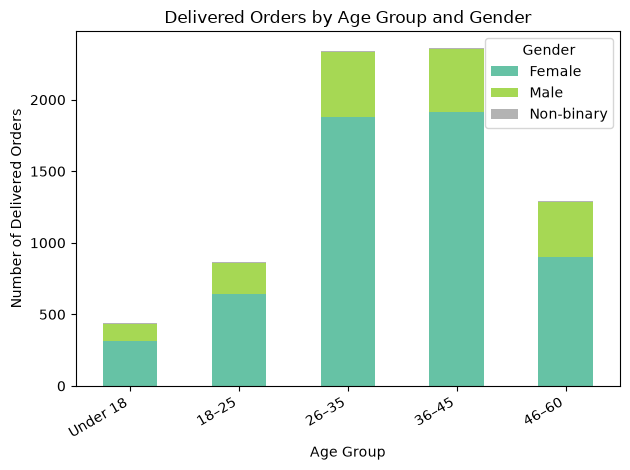

In [5]:
# 1. Which age group buys the most?

# Keep only delivered orders
delivered = orders[orders["status"].astype(str).str.lower() == "delivered"].copy()

# Add customer age and gender to each order
orders_customers = delivered.merge(customers[["customer_id", "age", "gender"]], on="customer_id",how="left")

# Create age groups
orders_customers["age_group"] = pd.cut(orders_customers["age"],
    bins=[0, 17, 25, 35, 45, 60, float("inf")],
    labels=["Under 18", "18–25", "26–35", "36–45", "46–60", "60+"],
    include_lowest=True )

# Count delivered orders by age group and gender
age_gender_orders = pd.crosstab(orders_customers["age_group"],orders_customers["gender"])

print(age_gender_orders)

# Plot stacked bar chart
ax = age_gender_orders.plot(kind="bar", stacked=True,colormap="Set2")

ax.set_title("Delivered Orders by Age Group and Gender")
ax.set_xlabel("Age Group")
ax.set_ylabel("Number of Delivered Orders")
ax.legend(title="Gender")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Top 10 City and Customer Segment Combinations by Revenue:
       city    customer_segment  net_revenue
     Mumbai        Value Seeker 1149224.2160
     Mumbai   Skincare Loyalist  899320.9235
     Mumbai     Beauty Explorer  769313.4175
     Mumbai       Premium Buyer  671333.3135
      Thane        Value Seeker  538168.3940
       Pune        Value Seeker  530465.5755
Navi Mumbai   Skincare Loyalist  492813.9945
     Mumbai Practical Household  450923.3030
Navi Mumbai        Value Seeker  442326.2630
Navi Mumbai Practical Household  393541.0560


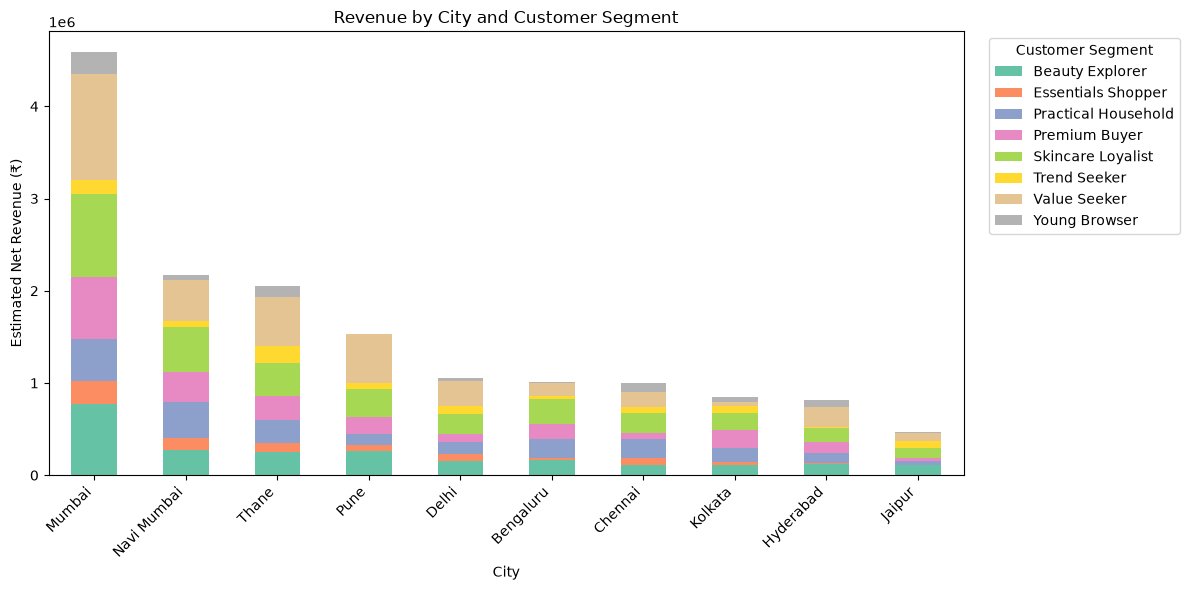

In [6]:
# 2. Which city generates the most revenue?

# Calculate revenue after discount
delivered["net_revenue"] = (delivered["price"] * (1 - delivered["discount_pct"] / 100))

# Add city and customer segment to each delivered order
orders_city = delivered.merge(customers[["customer_id", "city", "customer_segment"]], on="customer_id", how="left")

# Calculate revenue by city and customer segment
city_segment_revenue = (orders_city.groupby(["city", "customer_segment"])["net_revenue"].sum().reset_index()
    .sort_values("net_revenue", ascending=False))

print("Top 10 City and Customer Segment Combinations by Revenue:")
print(city_segment_revenue.head(10).to_string(index=False))

# Pivot data for stacked bar chart
top_cities = (orders_city.groupby("city")["net_revenue"].sum().nlargest(10).index)

top_city_data = orders_city[orders_city["city"].isin(top_cities)]

city_segment_pivot = top_city_data.pivot_table(
    index="city",
    columns="customer_segment",
    values="net_revenue",
    aggfunc="sum",
    fill_value=0
)

# Sort cities by total revenue
city_segment_pivot = city_segment_pivot.loc[city_segment_pivot.sum(axis=1).sort_values(ascending=False).index]

# Plot stacked bar chart
ax = city_segment_pivot.plot(kind="bar", stacked=True, figsize=(12, 6), colormap="Set2")

ax.set_title("Revenue by City and Customer Segment")
ax.set_xlabel("City")
ax.set_ylabel("Estimated Net Revenue (₹)")
ax.legend(title="Customer Segment", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Top-Selling Products by Delivered Orders
                     Delivered Orders  Share (%)
product_name                                    
Aloe Gel                          361       4.95
Face Toner                        355       4.86
Skincare Product 68               337       4.62
Skincare Product 82               267       3.66
Denim Jeans                       242       3.32
Under-Eye Cream                   237       3.25
Gentle Cleanser                   226       3.10
Minimalist Watch                  222       3.04
Clay Mask                         214       2.93
Vitamin C Serum                   193       2.64
Other products                   4646      63.64


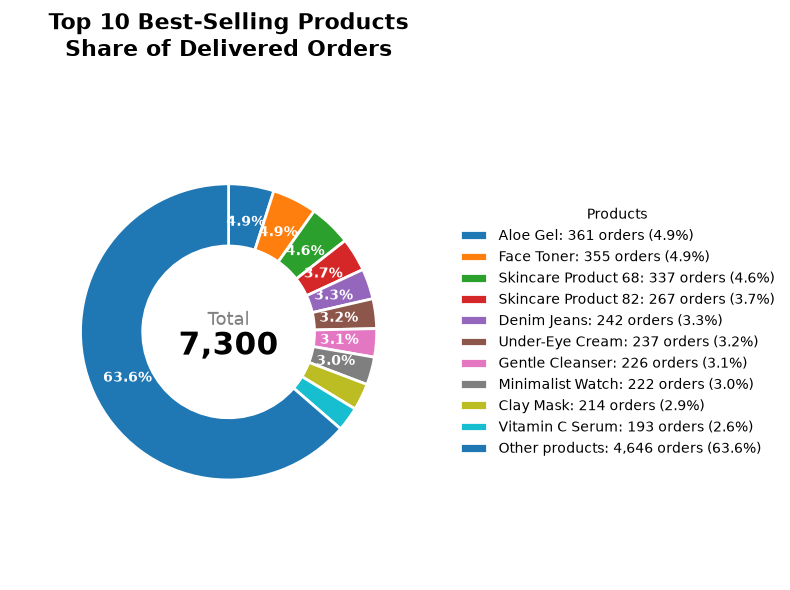

In [7]:
# 3. Which products sell the most

# Attach product names to delivered orders
orders_products = delivered.merge(
    products[["product_id", "product_name"]],
    on="product_id",
    how="left"
)

# Count delivered orders per product
product_sales = (
    orders_products.groupby("product_name")["order_id"]
    .nunique()
    .sort_values(ascending=False)
)

# Select top 10 products
top_10_sales = product_sales.head(10)

# Group remaining products
other_sales = product_sales.iloc[10:].sum()

pie_sales = top_10_sales.copy()
if other_sales > 0:
    pie_sales["Other products"] = other_sales

# Print top products with percentages
sales_percentage = (pie_sales / pie_sales.sum() * 100)

product_summary = pd.DataFrame({
    "Delivered Orders": pie_sales,
    "Share (%)": sales_percentage.round(2)
})

print("Top-Selling Products by Delivered Orders")
print(product_summary.to_string())

# Create a polished donut chart
fig, ax = plt.subplots(figsize=(8, 6))

colors = sns.color_palette("tab10", len(pie_sales))

wedges, texts, autotexts = ax.pie(
    pie_sales.values,
    labels=None,
    autopct=lambda pct: f"{pct:.1f}%" if pct >= 3 else "",
    startangle=90,
    counterclock=False,
    colors=colors,
    pctdistance=0.75,
    wedgeprops={"width": 0.42, "edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 10}
)

# Improve percentage labels
for text in autotexts:
    text.set_fontweight("bold")
    text.set_color("white")

# Show total orders in the center
total_orders = int(pie_sales.sum())

ax.text(
    0, 0.08, "Total",
    ha="center", va="center",
    fontsize=13, color="gray"
)
ax.text(
    0, -0.10, f"{total_orders:,}",
    ha="center", va="center",
    fontsize=22, fontweight="bold"
)

# Add legend with product names and order counts
legend_labels = [
    f"{name}: {count:,} orders ({sales_percentage[name]:.1f}%)"
    for name, count in pie_sales.items()
]

ax.legend(
    wedges,
    legend_labels,
    title="Products",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    frameon=False,
    fontsize=10
)

ax.set_title(
    "Top 10 Best-Selling Products\nShare of Delivered Orders",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.axis("equal")
plt.tight_layout()
plt.show()

Top 10 Products by Repeat Customers:
product_name
Aloe Gel               23
Skincare Product 68    20
Skincare Product 82    19
Face Toner             19
Gentle Cleanser        13
Under-Eye Cream        13
Clay Mask              10
Denim Jeans             9
Minimalist Watch        8
Sunscreen SPF 50        6
Other products         81


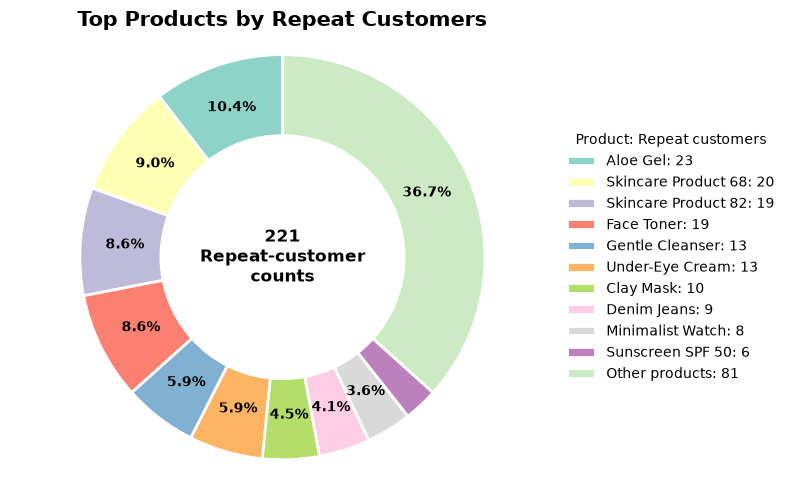

In [8]:
# 4. Which products are bought repeatedly?

# Count repeat purchases by customer and product
repeat_purchases = (
    orders_products.groupby(["customer_id", "product_name"])["order_id"]
    .nunique().reset_index(name="orders")
    .query("orders >= 2")
)

# Count repeat customers per product
repeat_sales = repeat_purchases.groupby("product_name")["customer_id"].nunique().sort_values(ascending=False)

# Top 10 + other products
pie_data = repeat_sales.head(10).copy()
if repeat_sales.iloc[10:].sum() > 0:
    pie_data["Other products"] = repeat_sales.iloc[10:].sum()

print("Top 10 Products by Repeat Customers:")
print(pie_data.to_string())

# Donut chart
if not pie_data.empty and pie_data.sum() > 0:
    fig, ax = plt.subplots(figsize=(8, 5))
    wedges, _, autotexts = ax.pie(
        pie_data, startangle=90,
        autopct=lambda p: f"{p:.1f}%" if p >= 3 else "",
        pctdistance=0.78,
        colors=sns.color_palette("Set3", len(pie_data)),
        wedgeprops=dict(width=0.4, edgecolor="white", linewidth=2)
    )

    for t in autotexts:
        t.set_fontweight("bold")

    ax.text(0, 0, f"{pie_data.sum():,}\nRepeat-customer\ncounts",
            ha="center", va="center", fontsize=12, fontweight="bold")

    ax.legend(wedges, [f"{p}: {n:,}" for p, n in pie_data.items()],
              title="Product: Repeat customers", bbox_to_anchor=(1, 0.5),
              loc="center left", frameon=False)

    ax.set_title("Top Products by Repeat Customers", fontsize=15, fontweight="bold")
    ax.axis("equal")
    plt.tight_layout()
    plt.show()
else:
    print("No repeat purchases found in delivered orders.")